In [1]:
# Manipulação de matrizes e tabelas
import numpy as np
import pandas as pd

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Pré-processamento e Modelagem (Scikit-Learn)
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# Modelagem Hierárquica (SciPy)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist

# Configuração visual dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [3]:
# Criando 300 observações com 3 centros reais no espaço bidimensional
X_puro, y_real = make_blobs(n_samples=300, centers=3, cluster_std=1.2, random_state=42)

# Criando um DataFrame
df = pd.DataFrame(X_puro, columns=['V1_Renda_Milhares', 'V2_Idade'])

# Propositadamente multipliquei a coluna de renda por 1000 para criar diferença de escala
df['V1_Renda_Milhares'] = df['V1_Renda_Milhares'] * 1000

print(df.describe().round(2))

       V1_Renda_Milhares  V2_Idade
count             300.00    300.00
mean            -1591.40      1.35
std              4965.03      6.68
min             -9845.60     -9.64
25%             -6115.06     -6.20
50%             -2551.52      1.99
75%              3797.57      8.15
max              7417.47     12.28


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Convertendo de volta para DataFrame só para inspecionar
df_scaled = pd.DataFrame(X_scaled, columns=['V1_padronizada', 'V2_padronizada'])

print("Médias após padronização:", np.round(df_scaled.mean().values, 4))
print("Desvios padrão após padronização:", np.round(df_scaled.std().values, 4))

Médias após padronização: [ 0. -0.]
Desvios padrão após padronização: [1.0017 1.0017]


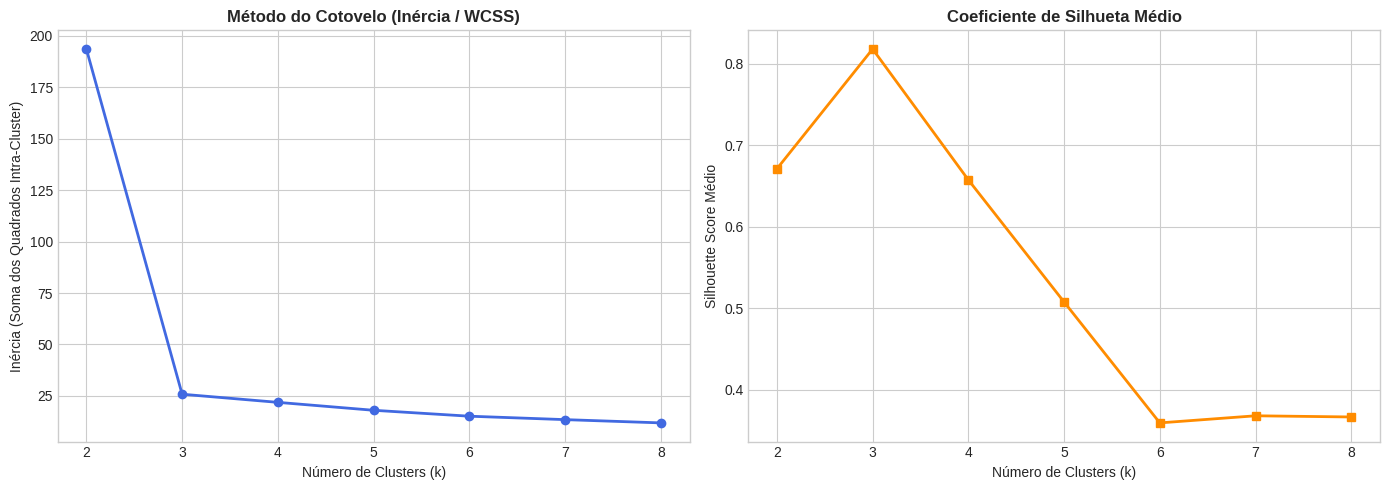

   k   Inércia  Silhueta
0  2  193.5698    0.6712
1  3   25.8149    0.8182
2  4   21.8577    0.6576
3  5   18.0037    0.5077
4  6   15.1306    0.3593
5  7   13.4621    0.3680
6  8   11.8764    0.3666


In [5]:
k_valores = list(range(2, 9))
inercias = []
silhuetas = []

for k in k_valores:
    # n_init=10 roda 10 inicializações aleatórias de centroides para evitar mínimos locais
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    
    # 1. Guarda a Inércia (WCSS)
    inercias.append(kmeans.inertia_)
    
    # 2. Calcula a Silhueta média
    score_sil = silhouette_score(X_scaled, labels)
    silhuetas.append(score_sil)

# Plotando os dois gráficos lado a lado
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Elbow (Inércia)
ax[0].plot(k_valores, inercias, marker='o', color='royalblue', linewidth=2)
ax[0].set_title("Método do Cotovelo (Inércia / WCSS)", fontsize=12, fontweight='bold')
ax[0].set_xlabel("Número de Clusters (k)")
ax[0].set_ylabel("Inércia (Soma dos Quadrados Intra-Cluster)")

# Gráfico 2: Silhueta
ax[1].plot(k_valores, silhuetas, marker='s', color='darkorange', linewidth=2)
ax[1].set_title("Coeficiente de Silhueta Médio", fontsize=12, fontweight='bold')
ax[1].set_xlabel("Número de Clusters (k)")
ax[1].set_ylabel("Silhouette Score Médio")

plt.tight_layout()
plt.show()

# Imprime os valores tabulados para análise técnica
resultados = pd.DataFrame({'k': k_valores, 'Inércia': inercias, 'Silhueta': silhuetas})
print(resultados.round(4))

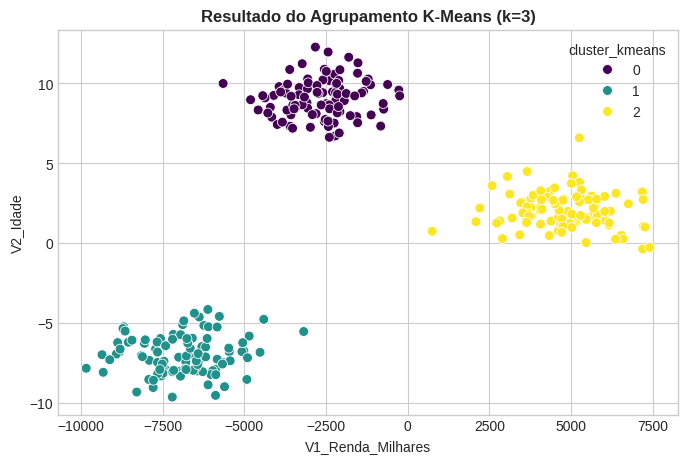

In [6]:
k_otimo = 3
kmeans_final = KMeans(n_clusters=k_otimo, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans_final.fit_predict(X_scaled)

# Visualizando os grupos formados e os centroides
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, 
    x='V1_Renda_Milhares', 
    y='V2_Idade', 
    hue='cluster_kmeans', 
    palette='viridis', 
    s=50
)
plt.title(f"Resultado do Agrupamento K-Means (k={k_otimo})", fontweight='bold')
plt.show()

In [7]:
perfil_kmeans = df.groupby('cluster_kmeans')[['V1_Renda_Milhares', 'V2_Idade']].agg(['mean', 'median', 'count'])
print("--- Perfil dos Clusters (K-Means) ---")
print(perfil_kmeans.round(2))

--- Perfil dos Clusters (K-Means) ---
               V1_Renda_Milhares                V2_Idade             
                            mean   median count     mean median count
cluster_kmeans                                                       
0                       -2658.04 -2551.52   100     9.05   9.21   100
1                       -6884.72 -6790.27   100    -7.00  -7.12   100
2                        4768.55  4743.56   100     2.02   1.99   100
